# SimBench study cases against the profiles

SimBench ships two kinds of operating points with every network:

- **Profiles**: a year of quarter-hour time series per element class (household H0-A…G,
  heat pumps, EV charging, PV1…PV8, ...), scaled by each element's rated power. The
  market uses these, through `background = "profiles"` and the participants' own elements
  ([`_absolute_profiles`](../../core/grid/simbench.py#L702-L705)).
- **Study cases**: six fixed snapshots for **planning** (SimBench documentation §5.1,
  [SimBench §6](../../docs/using/data/simbench.md#6-study-cases)): every element's
  **rated** power times one factor per element type, plus a set point for the upstream
  voltage. Nothing in V2 uses them.

This notebook shows what each case is, how it loads our network (`1-LV-rural3--2-sw`, the
network of `lv_rural3_p13`) compared with the profile year, and how every LV network
behaves under both. Only SimBench and pandapower are called; nothing of the market.

In [1]:
import copy
import json
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "core").is_dir())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import pandapower as pp
import pandapower.topology as top
import simbench as sb

GRID = json.loads((ROOT / "config/archive/scenarios/lv_rural3_p13.json").read_text())["grid"]
CODE = GRID["code"]
LIMITS = dict(line=GRID["line_max_percent"], trafo=100.0, v_min=GRID["v_min_pu"], v_max=GRID["v_max_pu"])
CASES = ["hL", "n1", "hW", "hPV", "lW", "lPV"]
pd.set_option("display.precision", 3)
CODE, LIMITS

('1-LV-rural3--2-sw',
 {'line': 100.0, 'trafo': 100.0, 'v_min': 0.95, 'v_max': 1.05})

## 1. What a study case is

`net.loadcases` holds the factors. They depend only on the voltage level of the network,
not on the network: every LV network has the same table, every MV network the same, HV
differs only in the low-load factor (0.25 instead of 0.1) and its set points.
`Slack_vm` is the voltage set at the external grid, i.e. at the upstream side of the
network's transformer; for an LV network a low 0.965 pu in the high-load cases (the MV
network is already sagging) and a high 1.055 pu in the low-load cases.

In [2]:
factors = {
    level: sb.get_simbench_net(code).loadcases
    for level, code in [("LV", CODE), ("MV", "1-MV-rural--2-sw"), ("HV", "1-HV-mixed--2-sw")]
}
pd.concat(factors, names=["level"]).round(3)

pload  qload  Wind_p  PV_p  RES_p  Slack_vm
level Study Case                                             
LV    hL           1.00  1.000    0.00  0.00    0.0     0.965
      n1           1.00  1.000    0.00  0.00    0.0     0.965
      hW           1.00  1.000    1.00  0.80    1.0     0.965
      hPV          1.00  1.000    0.85  0.95    1.0     0.965
      lW           0.10  0.123    1.00  0.80    1.0     1.055
      lPV          0.10  0.123    0.85  0.95    1.0     1.055
MV    hL           1.00  1.000    0.00  0.00    0.0     1.035
      n1           1.00  1.000    0.00  0.00    0.0     1.035
      hW           1.00  1.000    1.00  0.80    1.0     1.035
      hPV          1.00  1.000    0.85  0.95    1.0     1.035
      lW           0.10  0.123    1.00  0.80    1.0     1.015
      lPV          0.10  0.123    0.85  0.95    1.0     1.015
HV    hL           1.00  1.000    0.00  0.00    0.0     1.025
      n1           1.00  1.000    0.00  0.00    0.0     1.025
      hW           1.00  1.000    1.00  0.80    1.0     1.025
      hPV          1.00  1.000    0.85  0.95    1.0     1.025
      lW           0.25  0.306    1.00  0.80    1.0     1.025
      lPV          0.25  0.306    0.85  0.95    1.0     1.025

SimBench applies them with `get_absolute_values(net, profiles_instead_of_study_cases=False)`:
one row per case (plus `bc`, the base case: every element at its rated power), one column
per element. PV and wind take their own factor, every other generator `RES_p`; loads take
`pload` and `qload`. Storage has no study-case values; here it is set to 0 (idle) in every case.
The profiles, for their part, leave `ext_grid.vm_pu` at its static value (1.025 pu for
this network) all year: the upstream voltage never moves in the time series.

In [3]:
net0 = sb.get_simbench_net(CODE)
case_values = sb.get_absolute_values(net0, profiles_instead_of_study_cases=False)
profiles = sb.get_absolute_values(net0, profiles_instead_of_study_cases=True)
print({k: v.shape for k, v in case_values.items()})
print("storage static p_mw:", net0.storage.p_mw.abs().sum())

{('ext_grid', 'vm_pu'): (7, 1), ('load', 'p_mw'): (7, 153), ('load', 'q_mvar'): (7, 153), ('sgen', 'p_mw'): (7, 27)}

storage static p_mw:

0.093

## 2. Rated power against what the profiles ever reach at once

The cases put every load at its rated power **at the same moment**. In the profiles each
load does reach its rated power, at its own peak, but not together: the ratio of the
highest simultaneous total to the rated total is the coincidence factor.

In [4]:
def hourly(df):
    # the market's hourly steps: the mean of each hour's four quarter hours
    return df.groupby(np.arange(len(df)) // 4).mean()

load_p, pv_p = hourly(profiles[("load", "p_mw")]), hourly(profiles[("sgen", "p_mw")])
rated_load, rated_pv = net0.load.p_mw.sum(), net0.sgen.p_mw.sum()

coincidence = pd.DataFrame({
    "rated total (kW)": [rated_load * 1e3, rated_pv * 1e3],
    "sum of each element's own max (kW)": [load_p.max().sum() * 1e3, pv_p.max().sum() * 1e3],
    "highest simultaneous total (kW)": [load_p.sum(axis=1).max() * 1e3, pv_p.sum(axis=1).max() * 1e3],
}, index=["load", "PV"])
coincidence["coincidence"] = coincidence.iloc[:, 2] / coincidence.iloc[:, 0]
coincidence.round(2)

,rated total (kW),sum of each element's own max (kW),highest simultaneous total (kW),coincidence
load,552.8,460.83,225.20,0.41
PV,252.3,152.29,141.38,0.56


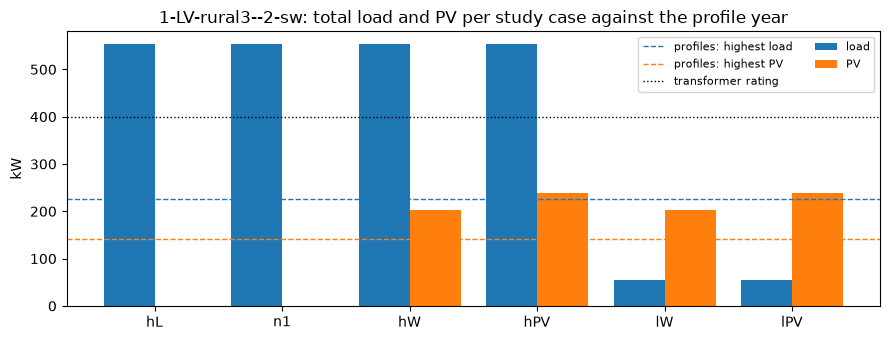

In [5]:
cases_total = pd.DataFrame({
    "load": case_values[("load", "p_mw")].sum(axis=1) * 1e3,
    "PV": case_values[("sgen", "p_mw")].sum(axis=1) * 1e3,
}).loc[CASES]

fig, ax = plt.subplots(figsize=(9, 3.5))
x = np.arange(len(CASES))
ax.bar(x - 0.2, cases_total["load"], 0.4, label="load", color="tab:blue")
ax.bar(x + 0.2, cases_total["PV"], 0.4, label="PV", color="tab:orange")
ax.axhline(load_p.sum(axis=1).max() * 1e3, color="tab:blue", ls="--", lw=1, label="profiles: highest load")
ax.axhline(pv_p.sum(axis=1).max() * 1e3, color="tab:orange", ls="--", lw=1, label="profiles: highest PV")
ax.axhline(net0.trafo.sn_mva.sum() * 1e3, color="k", ls=":", lw=1, label="transformer rating")
ax.set_xticks(x, CASES); ax.set_ylabel("kW"); ax.legend(fontsize=8, ncol=2)
ax.set_title(f"{CODE}: total load and PV per study case against the profile year")
plt.tight_layout()

## 3. The power flow of each case on our network

In [6]:
def set_case(net, case):
    # the network at one study case
    for (table, column), df in case_values_of(net).items():
        net[table].loc[df.columns, column] = df.loc[case].values
    if len(net.storage):
        net.storage.p_mw = 0.0
    return net

_values = {}
def case_values_of(net):
    key = id(net)
    if key not in _values:
        _values[key] = sb.get_absolute_values(net, profiles_instead_of_study_cases=False)
    return _values[key]

def summary(net):
    return dict(
        line_max=net.res_line.loading_percent.max(),
        trafo_max=net.res_trafo.loading_percent.max(),
        v_min=net.res_bus.vm_pu.min(),
        v_max=net.res_bus.vm_pu.max(),
        lines_over=int((net.res_line.loading_percent > LIMITS["line"]).sum()),
        buses_out=int(((net.res_bus.vm_pu < LIMITS["v_min"]) | (net.res_bus.vm_pu > LIMITS["v_max"])).sum()),
    )

case_nets = {}
for case in CASES:
    net = set_case(copy.deepcopy(net0), case)
    _values[id(net)] = case_values  # same network, same values
    pp.runpp(net)
    case_nets[case] = net

case_table = pd.DataFrame({c: summary(n) for c, n in case_nets.items()}).T
case_table

,line_max,trafo_max,v_min,v_max,lines_over,buses_out
hL,106.609,169.472,0.856,0.965,3.0,128.0
n1,106.609,169.472,0.856,0.965,3.0,128.0
hW,99.956,116.422,0.877,0.965,0.0,128.0
hPV,98.762,107.398,0.880,0.965,0.0,128.0
lW,29.557,35.083,1.054,1.069,0.0,129.0
lPV,35.685,43.785,1.055,1.073,0.0,129.0


`n1` is `hL` again: it is meant for contingency checks (one element out), which a radial
LV network without meshing has no use for, so it gives the same numbers.

## 4. Voltage along the feeders

Each bus's voltage against its line distance from the transformer, for the two extreme
cases and for the profile year's two extreme hours (the highest net load and the highest
net feed-in, background and all participants on their profiles).

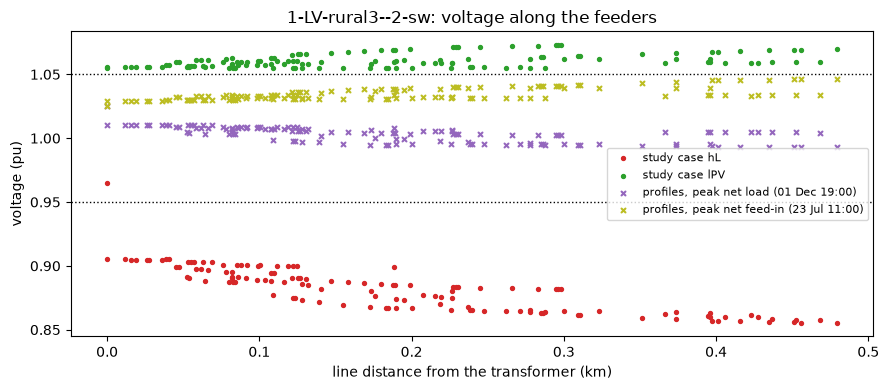

In [7]:
lv_bus = int(net0.trafo.lv_bus.iloc[0])
graph = top.create_nxgraph(net0, calc_branch_impedances=False)
distance = pd.Series(nx.single_source_dijkstra_path_length(graph, lv_bus, weight="weight"))

def set_hour(net, hour):
    # the network at one hour of the profile year (hourly mean, as the market)
    for (table, column), df in profiles.items():
        if table in ("load", "sgen", "storage") and not df.empty:
            net[table].loc[df.columns, column] = df.iloc[4 * hour: 4 * hour + 4].mean().values
    return net

net_load = load_p.sum(axis=1) - pv_p.sum(axis=1)
peak_hour, feed_hour = int(net_load.idxmax()), int(net_load.idxmin())
when = lambda h: (pd.Timestamp("2016-01-01") + pd.Timedelta(hours=h)).strftime("%d %b %H:00")

hour_nets = {}
for label, hour in [(f"profiles, peak net load ({when(peak_hour)})", peak_hour),
                    (f"profiles, peak net feed-in ({when(feed_hour)})", feed_hour)]:
    net = set_hour(copy.deepcopy(net0), hour)
    pp.runpp(net)
    hour_nets[label] = net

fig, ax = plt.subplots(figsize=(9, 4))
styles = {"hL": "tab:red", "lPV": "tab:green"}
for case, color in styles.items():
    v = case_nets[case].res_bus.vm_pu
    ax.scatter(distance.reindex(v.index), v, s=8, color=color, label=f"study case {case}")
for (label, net), color in zip(hour_nets.items(), ["tab:purple", "tab:olive"]):
    v = net.res_bus.vm_pu
    ax.scatter(distance.reindex(v.index), v, s=8, color=color, marker="x", label=label)
for lim in (LIMITS["v_min"], LIMITS["v_max"]):
    ax.axhline(lim, color="k", ls=":", lw=1)
ax.set_xlabel("line distance from the transformer (km)"); ax.set_ylabel("voltage (pu)")
ax.legend(fontsize=8); ax.set_title(f"{CODE}: voltage along the feeders")
plt.tight_layout()

## 5. The whole profile year against the cases

One power flow per hour of 2016 (hourly means, as the market steps), every element on its
profile and no market: about two minutes. Duration curves: each quantity sorted from the
highest hour to the lowest, with the study cases as horizontal lines.

In [8]:
year_net = copy.deepcopy(net0)
rows = []
for hour in range(len(load_p)):
    set_hour(year_net, hour)
    pp.runpp(year_net, recycle=dict(trafo=False, gen=False, bus_pq=True))
    rows.append(summary(year_net))
year = pd.DataFrame(rows, index=pd.date_range("2016-01-01", periods=len(rows), freq="h"))
year[["line_max", "trafo_max", "v_min", "v_max", "lines_over", "buses_out"]].describe().loc[["mean", "50%", "max", "min"]]

,line_max,trafo_max,v_min,v_max,lines_over,buses_out
mean,10.048,12.388,1.018,1.026,0.0,0.0
50%,7.025,9.372,1.020,1.025,0.0,0.0
max,49.437,56.575,1.025,1.046,0.0,0.0
min,0.808,0.316,0.991,1.025,0.0,0.0


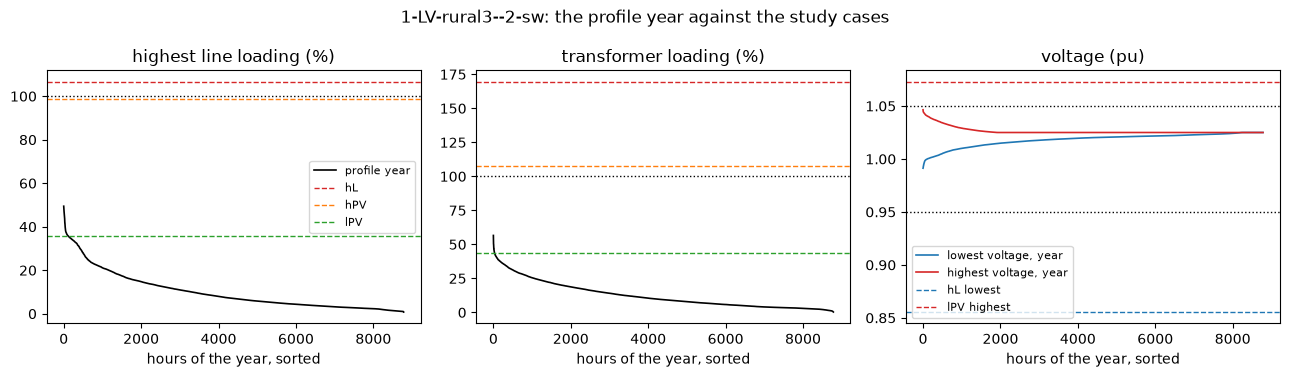

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
hours = np.arange(len(year))
for ax, col, title in [(axes[0], "line_max", "highest line loading (%)"),
                       (axes[1], "trafo_max", "transformer loading (%)")]:
    ax.plot(hours, year[col].sort_values(ascending=False).values, color="k", lw=1.2, label="profile year")
    for case, color in [("hL", "tab:red"), ("hPV", "tab:orange"), ("lPV", "tab:green")]:
        ax.axhline(case_table.loc[case, col], color=color, ls="--", lw=1, label=case)
    ax.axhline(100, color="k", ls=":", lw=1)
    ax.set_title(title); ax.set_xlabel("hours of the year, sorted")
axes[0].legend(fontsize=8)
ax = axes[2]
ax.plot(hours, year.v_min.sort_values().values, color="tab:blue", lw=1.2, label="lowest voltage, year")
ax.plot(hours, year.v_max.sort_values(ascending=False).values, color="tab:red", lw=1.2, label="highest voltage, year")
ax.axhline(case_table.loc["hL", "v_min"], color="tab:blue", ls="--", lw=1, label="hL lowest")
ax.axhline(case_table.loc["lPV", "v_max"], color="tab:red", ls="--", lw=1, label="lPV highest")
for lim in (LIMITS["v_min"], LIMITS["v_max"]):
    ax.axhline(lim, color="k", ls=":", lw=1)
ax.set_title("voltage (pu)"); ax.set_xlabel("hours of the year, sorted"); ax.legend(fontsize=8)
plt.suptitle(f"{CODE}: the profile year against the study cases")
plt.tight_layout()

In [10]:
monthly = year.resample("ME").agg({"line_max": "max", "trafo_max": "max", "v_min": "min", "v_max": "max"})
monthly.index = monthly.index.strftime("%b")
monthly.round(3).T

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
line_max,49.437,47.970,39.454,35.068,33.927,24.876,25.361,24.609,22.021,39.629,37.449,44.726
trafo_max,53.236,47.513,41.300,33.256,38.695,37.198,41.436,37.644,29.632,38.500,41.449,56.575
v_min,0.991,0.991,0.998,1.002,1.003,1.009,1.010,1.012,1.010,1.001,1.000,0.992
v_max,1.026,1.028,1.040,1.041,1.046,1.045,1.046,1.044,1.040,1.037,1.031,1.026


## 6. Every LV network: study cases and profile extremes

The six LV grids in the three scenarios (the `-sw` variants). For the profiles, instead of
the whole year, the 100 hours with the highest net load and the 100 with the highest net
feed-in (hourly means), where the extremes of the year lie. Each cell: the worst value
over those hours, or of the case.

In [11]:
LV_CODES = [f"1-LV-{g}--{s}-sw" for g in ("rural1", "rural2", "rural3", "semiurb4", "semiurb5", "urban6") for s in (0, 1, 2)]

def network_extremes(code, n_hours=100):
    base = sb.get_simbench_net(code)
    cv = sb.get_absolute_values(base, profiles_instead_of_study_cases=False)
    pr = sb.get_absolute_values(base, profiles_instead_of_study_cases=True)
    out = {}
    for case in ("hL", "hPV", "lPV"):
        net = copy.deepcopy(base)
        for (table, column), df in cv.items():
            net[table].loc[df.columns, column] = df.loc[case].values
        if len(net.storage):
            net.storage.p_mw = 0.0
        pp.runpp(net)
        out[case] = summary(net)
    lp, sp = hourly(pr[("load", "p_mw")]), hourly(pr[("sgen", "p_mw")])
    nl = lp.sum(axis=1) - sp.sum(axis=1)
    picked = list(nl.nlargest(n_hours).index) + list(nl.nsmallest(n_hours).index)
    net, rows = copy.deepcopy(base), []
    for hour in picked:
        for (table, column), df in pr.items():
            if table in ("load", "sgen", "storage") and not df.empty:
                net[table].loc[df.columns, column] = df.iloc[4 * hour: 4 * hour + 4].mean().values
        pp.runpp(net, recycle=dict(trafo=False, gen=False, bus_pq=True))
        rows.append(summary(net))
    r = pd.DataFrame(rows)
    out["profiles"] = dict(line_max=r.line_max.max(), trafo_max=r.trafo_max.max(), v_min=r.v_min.min(),
                           v_max=r.v_max.max(), lines_over=int(r.lines_over.max()), buses_out=int(r.buses_out.max()))
    return pd.DataFrame(out).T

networks = pd.concat({code.replace("1-LV-", "").replace("-sw", ""): network_extremes(code) for code in LV_CODES},
                     names=["network", "operating point"])
with pd.option_context("display.max_rows", 200):
    display(networks[["line_max", "trafo_max", "v_min", "v_max", "lines_over"]]
            .unstack("operating point").round(2))

line_max                        trafo_max                  \
operating point       hL    hPV    lPV profiles        hL     hPV     lPV   
network                                                                     
rural1--0          22.54  40.91  45.37    25.33     57.10   51.03   84.52   
rural1--1          22.49  63.86  69.98    71.14     58.41  227.86  247.95   
rural1--2          55.66  53.02  68.95    71.08    132.18  173.66  242.71   
rural2--0          72.48  52.69  25.83    24.74     94.92   44.16   44.43   
rural2--1          75.20  42.08  51.98    28.03    102.36   36.82   73.38   
rural2--2          91.36  55.66  51.71    40.75    159.14   74.07   71.19   
rural3--0          47.52  33.28  19.61    19.35     97.26   53.81   34.98   
rural3--1          87.20  79.92  30.89    37.48    145.71   87.70   43.10   
rural3--2         106.61  98.76  35.69    49.44    169.47  107.40   43.78   
semiurb4--0        69.26  67.40   6.10    38.45     70.76   69.17    5.41   
semiurb4--1        71.76  70.36   6.36    39.62     73.32   71.73    5.63   
semiurb4--2       106.12  83.32  59.67    85.43     99.59   59.71   30.31   
semiurb5--0        70.15  48.62  20.03    25.73     75.79   55.07   13.67   
semiurb5--1        84.21  51.30  28.74    26.38     87.75   60.24   19.05   
semiurb5--2       100.23  66.94  27.95    42.05    104.28   75.64   18.38   
urban6--0          66.71  60.80   8.67    23.04     81.37   72.68    3.56   
urban6--1          66.77  58.38  31.72    23.02     82.00   60.99   13.63   
urban6--2          94.09  72.10  34.83    29.12    116.63   89.97   15.70   

                         v_min                      v_max              \
operating point profiles    hL   hPV   lPV profiles    hL   hPV   lPV   
network                                                                 
rural1--0          41.37  0.94  0.96  1.06     1.01  0.96  0.97  1.07   
rural1--1         187.50  0.94  0.96  1.06     1.01  0.96  1.02  1.12   
rural1--2         203.76  0.91  0.96  1.06     1.01  0.96  0.99  1.12   
rural2--0          30.18  0.90  0.92  1.06     1.01  0.96  0.96  1.07   
rural2--1          41.76  0.89  0.93  1.06     1.01  0.96  0.96  1.08   
rural2--2          62.45  0.86  0.90  1.06     1.00  0.96  0.96  1.08   
rural3--0          32.18  0.90  0.92  1.06     1.00  0.96  0.96  1.07   
rural3--1          48.13  0.86  0.89  1.06     0.99  0.96  0.96  1.07   
rural3--2          56.57  0.86  0.88  1.05     0.99  0.96  0.96  1.07   
semiurb4--0        26.74  0.92  0.92  1.05     1.01  0.96  0.96  1.06   
semiurb4--1        27.16  0.91  0.92  1.05     1.00  0.96  0.96  1.06   
semiurb4--2        46.40  0.90  0.92  1.06     1.00  0.96  0.96  1.08   
semiurb5--0        24.56  0.91  0.92  1.05     1.01  0.96  0.96  1.07   
semiurb5--1        26.94  0.90  0.92  1.05     1.01  0.96  0.96  1.07   
semiurb5--2        30.31  0.89  0.91  1.05     1.01  0.96  0.96  1.07   
urban6--0          26.12  0.91  0.92  1.05     1.01  0.96  0.96  1.06   
urban6--1          25.78  0.91  0.92  1.05     1.01  0.96  0.96  1.07   
urban6--2          30.65  0.89  0.91  1.05     1.01  0.96  0.96  1.07   

                         lines_over                     
operating point profiles         hL  hPV  lPV profiles  
network                                                 
rural1--0           1.03        0.0  0.0  0.0      0.0  
rural1--1           1.07        0.0  0.0  0.0      0.0  
rural1--2           1.07        0.0  0.0  0.0      0.0  
rural2--0           1.03        0.0  0.0  0.0      0.0  
rural2--1           1.04        0.0  0.0  0.0      0.0  
rural2--2           1.04        0.0  0.0  0.0      0.0  
rural3--0           1.03        0.0  0.0  0.0      0.0  
rural3--1           1.05        0.0  0.0  0.0      0.0  
rural3--2           1.05        3.0  0.0  0.0      0.0  
semiurb4--0         1.02        0.0  0.0  0.0      0.0  
semiurb4--1         1.02        0.0  0.0  0.0      0.0  
semiurb4--2         1.06        2.0  0.0  0.0      0.0  
semiurb5-

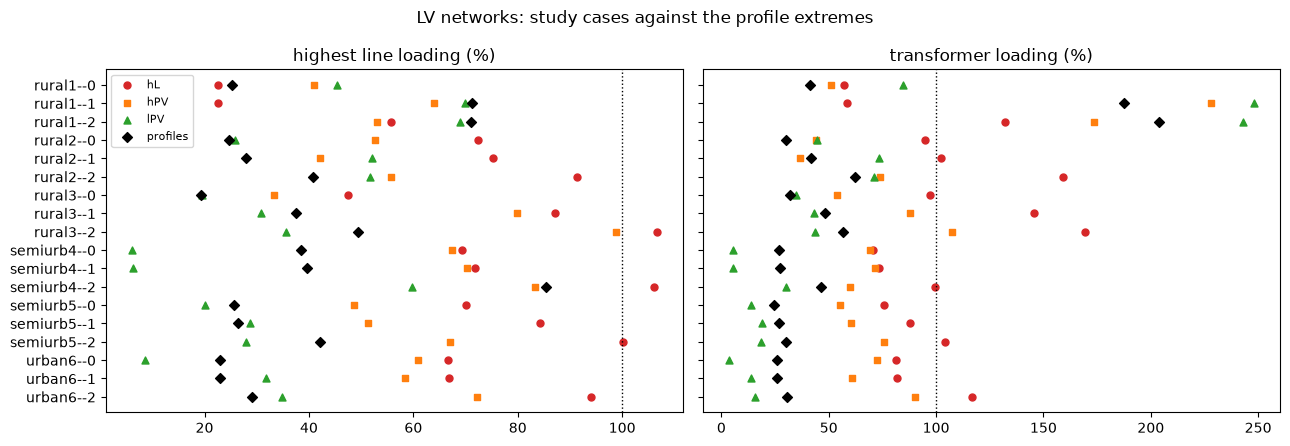

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
names = networks.index.get_level_values(0).unique()
y = np.arange(len(names))
marks = {"hL": ("tab:red", "o"), "hPV": ("tab:orange", "s"), "lPV": ("tab:green", "^"), "profiles": ("k", "D")}
for ax, col, title in [(axes[0], "line_max", "highest line loading (%)"), (axes[1], "trafo_max", "transformer loading (%)")]:
    for point, (color, marker) in marks.items():
        values = networks.xs(point, level=1)[col].reindex(names)
        ax.scatter(values, y, color=color, marker=marker, label=point, s=25)
    ax.axvline(100, color="k", ls=":", lw=1); ax.set_title(title)
axes[0].set_yticks(y, names); axes[0].invert_yaxis(); axes[0].legend(fontsize=8)
plt.suptitle("LV networks: study cases against the profile extremes")
plt.tight_layout()

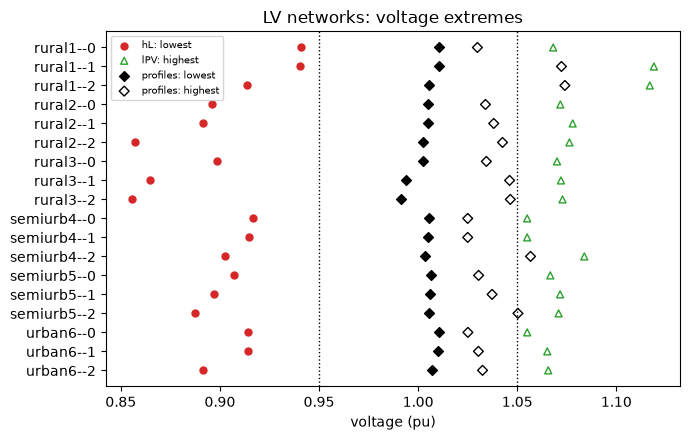

In [13]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for point, (color, marker) in marks.items():
    sub = networks.xs(point, level=1).reindex(names)
    if point in ("hL", "profiles"):
        ax.scatter(sub.v_min, y, color=color, marker=marker, s=25, label=f"{point}: lowest")
    if point in ("lPV", "profiles"):
        ax.scatter(sub.v_max, y, color=color, marker=marker, s=25, facecolors="none", label=f"{point}: highest")
for lim in (LIMITS["v_min"], LIMITS["v_max"]):
    ax.axvline(lim, color="k", ls=":", lw=1)
ax.set_yticks(y, names); ax.invert_yaxis(); ax.set_xlabel("voltage (pu)"); ax.legend(fontsize=7)
ax.set_title("LV networks: voltage extremes")
plt.tight_layout()

## 7. What it means for the market

Results of the run on 6 Nov 2026.

- **The study cases are planning extremes**: every load at its rated power at once
  (the profiles never draw more than 41 % of the rated load together on `rural3--2`), and
  the upstream voltage at 0.965 or 1.055 pu, which alone puts most LV buses outside a
  0.95-1.05 band. They overload the scenario-2 grids (`rural3--2` hL: line 107 %,
  transformer 169 %), but they are snapshots, not days: the market cannot play them as they are.
- **Under the profiles, most LV networks never come near a limit.** `rural3--2`, the
  network of every experiment so far, peaks at 49 % line and 57 % transformer loading over
  the year (25 % and 41 % in July); this is why the fees stay small.
- **The exception is `rural1` in scenarios 1 and 2**: 468 kW of PV behind a 160 kVA
  transformer. Under its plain profiles the transformer is overloaded on 613 hours of the
  year (reverse flow at midday, 9:00-15:00, March to October; up to 204 %), and the
  voltage exceeds 1.05 pu on 563 hours. July 1-14 alone has 36 overloaded hours.
  `semiurb4--2` reaches 85 % line loading with no overload.
- **The profiles hold the upstream voltage at its static value** (1.025 pu) all year.

So a market on `rural1--1`/`rural1--2` meets real congestion from the profiles alone,
in the direction a local market can relieve (absorbing PV in batteries and loads
locally); `rural3` needs a stress of its own (scaled profiles, a moving upstream
voltage) if the grid is to bind.